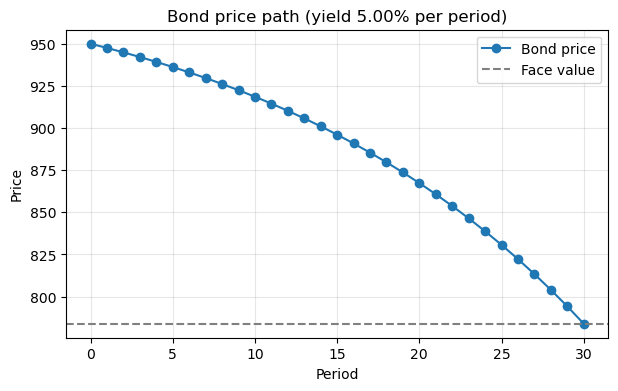

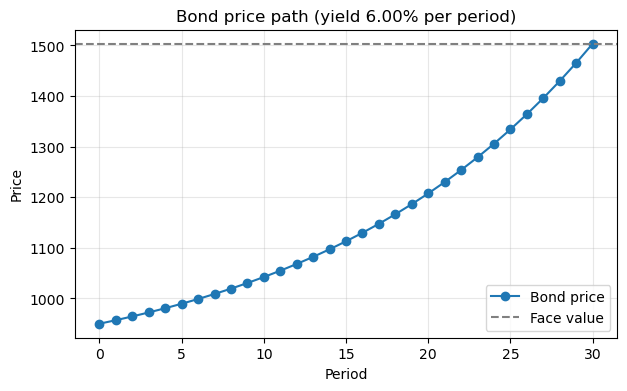

In [5]:
import math
import tkinter as tk
from tkinter import messagebox
import matplotlib.pyplot as plt   # NEW


def tvm(n=None, r=None, pv=None, pmt=None, fv=None):
    """
    Solve for whichever TVM variable is None.
    Equation (end-of-period payments, calculator sign convention):
        PV*(1+r)^n + PMT*((1+r)^n - 1)/r + FV = 0
    Outflows are negative, inflows positive.
    """
    args = {"n": n, "r": r, "pv": pv, "pmt": pmt, "fv": fv}
    missing = [k for k, v in args.items() if v is None]
    if len(missing) != 1:
        raise ValueError(f"Leave exactly ONE box blank. Blank now: {missing}")
    target = missing[0]

    if target != "r" and r == 0:
        raise ValueError("Rate of 0 is not supported.")

    if target == "fv":
        factor = (1 + r) ** n
        return -(pv * factor + pmt * (factor - 1) / r)

    if target == "pv":
        factor = (1 + r) ** n
        return -(fv + pmt * (factor - 1) / r) / factor

    if target == "pmt":
        factor = (1 + r) ** n
        return -(pv * factor + fv) / ((factor - 1) / r)

    if target == "n":
        growth = (pmt / r - fv) / (pv + pmt / r)
        if growth <= 0:
            raise ValueError("No solution for N with these inputs (check signs).")
        return math.log(growth) / math.log(1 + r)

    if target == "r":
        def f(rate):
            factor = (1 + rate) ** n
            return pv * factor + pmt * (factor - 1) / rate + fv

        low, high = 1e-9, 1.0
        if f(low) * f(high) > 0:
            raise ValueError("No rate found between 0% and 100% (check signs).")
        for _ in range(200):
            mid = (low + high) / 2
            if f(low) * f(mid) > 0:
                low = mid
            else:
                high = mid
        return (low + high) / 2


def price_path(n, r, pmt, fv):   # NEW
    """
    Bond price at each period t = 0..n, holding the yield r constant.
    The price at time t is simply the PV of the cash flows still remaining,
    so we reuse tvm() with (n - t) periods left.
    """
    n = int(round(n))
    path = []
    for t in range(n + 1):
        remaining = n - t
        if remaining == 0:
            price = fv                                        # at maturity: face value
        else:
            price = -tvm(n=remaining, r=r, pmt=pmt, fv=fv)   # flip sign: PV is an outflow
        path.append((t, price))
    return path


# ---------- GUI ----------
FIELDS = ["n", "r", "pv", "pmt", "fv"]
LABELS = {"n": "N (periods)", "r": "R (rate per period, e.g. 0.06)",
          "pv": "Present Value", "pmt": "Payment", "fv": "Future Value"}


def read_box(entry):
    text = entry.get().strip()
    return None if text == "" else float(text)


def show_price_path(values):   # NEW
    path = price_path(values["n"], values["r"], values["pmt"], values["fv"])

    # --- table window ---
    win = tk.Toplevel(root)
    win.title("Bond price over time")
    text = tk.Text(win, width=36, height=min(len(path) + 3, 30), font=("Courier", 11))
    text.pack(padx=10, pady=10)
    text.insert("end", f"{'Period':>8}  {'Price':>12}  {'Change':>10}\n")
    text.insert("end", "-" * 34 + "\n")
    prev = None
    for t, price in path:
        change = "" if prev is None else f"{price - prev:+10.2f}"
        text.insert("end", f"{t:>8}  {price:>12.2f}  {change:>10}\n")
        prev = price
    text.config(state="disabled")

    # --- chart ---
    periods = [t for t, _ in path]
    prices = [p for _, p in path]
    plt.figure(figsize=(7, 4))
    plt.plot(periods, prices, marker="o", label="Bond price")
    plt.axhline(values["fv"], linestyle="--", color="gray", label="Face value")
    plt.title(f"Bond price path (yield {values['r']:.2%} per period)")
    plt.xlabel("Period")
    plt.ylabel("Price")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


def on_calculate():
    try:
        values = {name: read_box(entries[name]) for name in FIELDS}
        missing = [k for k, v in values.items() if v is None]

        if len(missing) == 0:   # NEW: all five entered -> price path
            today = -tvm(n=values["n"], r=values["r"], pmt=values["pmt"], fv=values["fv"])
            result_label.config(
                text=f"Price today at {values['r']:.2%} = {today:,.2f}   "
                     f"(you entered PV = {values['pv']:,.2f})"
            )
            show_price_path(values)
            return

        result = tvm(**values)
        target = missing[0]
        if target == "r":
            result_label.config(text=f"R = {result:.4%} per period")
        else:
            result_label.config(text=f"{target.upper()} = {result:,.4f}")
    except ValueError as e:
        messagebox.showerror("Input error", str(e))
    except ZeroDivisionError:
        messagebox.showerror("Input error", "Division by zero — check your inputs.")


root = tk.Tk()
root.title("TVM Calculator")

entries = {}
for row, name in enumerate(FIELDS):
    tk.Label(root, text=LABELS[name]).grid(row=row, column=0, padx=8, pady=4, sticky="e")
    entry = tk.Entry(root, width=20)
    entry.grid(row=row, column=1, padx=8, pady=4)
    entries[name] = entry

tk.Button(root, text="Calculate", command=on_calculate).grid(
    row=len(FIELDS), column=0, columnspan=2, pady=10
)
result_label = tk.Label(
    root, text="Leave one box blank to solve it, or fill all five to see the price path."
)
result_label.grid(row=len(FIELDS) + 1, column=0, columnspan=2, pady=5)

root.mainloop()